### 0D solver class

In [89]:
import sys
RE_path = './' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

In [90]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp

In [91]:
import RE as RE
import importlib
importlib.reload(RE)

solver = RE.solver0D()
solver.display() # Show default values


Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 3


In [92]:
solver.n_imp = 1e20
solver.k = 1.70
solver.Ir0 = 1e4
solver.iDreicer = 0
solver.tmax = 3e-3
solver.display()

Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.700
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 1e+04
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e+20
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 0, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 3


Text(0.5, 1.0, 'k=1.7')

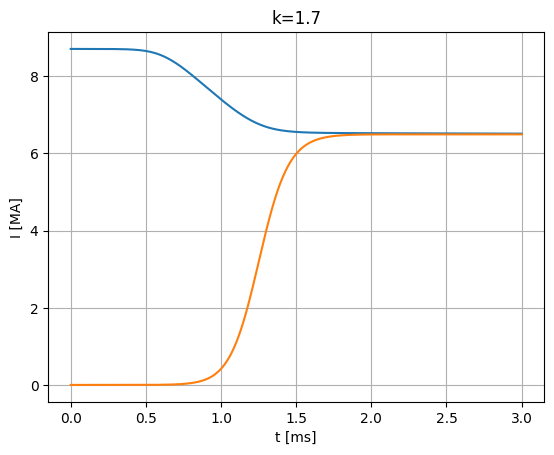

In [96]:
# solve

t, Ip, Ir, Wk = solver.solve()

plt.plot(t*1e3,Ip/1e6,label='Ip')
plt.plot(t*1e3,Ir/1e6,label='Ir')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.title(f'k={solver.k}')

Text(0, 0.5, 'I [MA]')

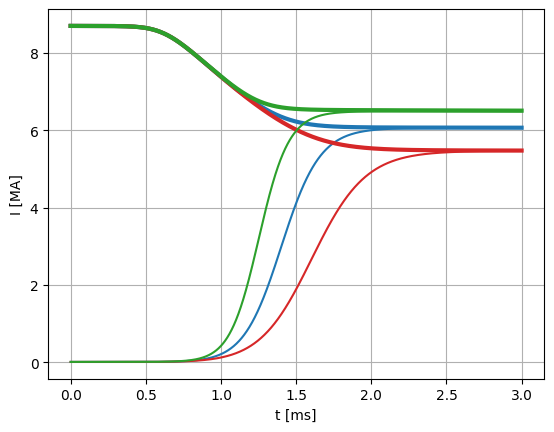

In [95]:
# Change settings and solve again

solver.iAvalanche = 1
t, Ip, Ir, Wk = solver.solve()
plt.plot(t*1e3,Ip/1e6,label='Ip',color='tab:blue',linewidth=3)
plt.plot(t*1e3,Ir/1e6,label='Ir',color='tab:blue')

solver.iAvalanche = 2
t, Ip, Ir, Wk = solver.solve()
plt.plot(t*1e3,Ip/1e6,label='Ip',color='tab:red',linewidth=3)
plt.plot(t*1e3,Ir/1e6,label='Ir',color='tab:red')

solver.iAvalanche = 3
t, Ip, Ir, Wk = solver.solve()
plt.plot(t*1e3,Ip/1e6,label='Ip',color='tab:green',linewidth=3)
plt.plot(t*1e3,Ir/1e6,label='Ir',color='tab:green')



plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')

In [36]:
for i in range(0, len(t), 100):
    print(f'time: {t[i]*1e3}, Ir Current: {Ir[i]/1e6}')

time: 0.0, Ir Current: 0.01
time: 0.030003000300030003, Ir Current: 0.01
time: 0.060006000600060005, Ir Current: 0.01
time: 0.09000900090009001, Ir Current: 0.01
time: 0.12001200120012001, Ir Current: 0.01
time: 0.15001500150015, Ir Current: 0.010000626990659713
time: 0.18001800180018002, Ir Current: 0.010003256136089114
time: 0.21002100210021002, Ir Current: 0.010006652984537045
time: 0.24002400240024002, Ir Current: 0.010010975908242941
time: 0.27002700270027, Ir Current: 0.010018114452515006
time: 0.3000300030003, Ir Current: 0.010031689335730221
time: 0.33003300330033003, Ir Current: 0.010057052449334337
time: 0.36003600360036003, Ir Current: 0.010101286857841884
time: 0.39003900390039004, Ir Current: 0.010173206798836156
time: 0.42004200420042004, Ir Current: 0.010283357700276243
time: 0.4500450045004501, Ir Current: 0.010454399330232894
time: 0.48004800480048004, Ir Current: 0.01071340902084642
time: 0.51005100510051, Ir Current: 0.011103015486260706
time: 0.54005400540054, Ir Cu

In [88]:
import scipy
print(scipy.__version__)

1.16.2
